# 소송특허 후보군 탐색

**목표**: 원고 특허가 주어졌을 때, 소송 대상이 될 피고 특허 후보를 추출 → 이후 예측 모델 입력

## 데이터 현황
- `sued_pairs_266cases.csv`: 269 케이스, 2508 원고-피고 특허 쌍
  - 원고 특허 709개 / 피고 특허 672개 (양쪽 모두 GNN node_idx 보유)
  - split: train 2198 / val 145 / test 165
- GNN 임베딩 (20260721): SAGEFraud·GAT·HeteroGAT·HeteroSAGE (각 256-dim, 556만 특허)
- 특허 피처 22개 (patent_features.parquet)
- **주의**: GNN은 is_litigated (원고 여부) 기준으로 학습 → 피고 특허는 대부분 0으로 처리됨

## 문제 정의 (2-Stage)
```
Stage 1 (Retrieval): 원고 특허 → 후보 피고 특허 Top-K 추출  ← 여기가 핵심 난이도
Stage 2 (Ranking) : Top-K 후보에서 실제 소송 대상 예측 (LightGBM 등)

Metric: Recall@K (후보 안에 실제 피고가 들어오는지)
```

---

## Stage 1: 후보군 추출 전략

### 전략 A — GNN 임베딩 유사도
원고 특허 임베딩과 cosine similarity 높은 특허 Top-K
- 장점: 전체 556만 특허 검색 가능, 빠름
- 한계: GNN이 원고(is_litigated=1) 기준으로 학습됨 → 피고 임베딩 표현력 약할 수 있음
- **먼저 Recall@K 측정해서 기준선 확인 필요**

### 전략 B — IPC 서브클래스 매칭
원고 특허의 IPC 4자리 코드와 동일한 특허 풀
- 장점: 기술 영역 직접 반영, 해석 용이
- 한계: 후보 수가 수만~수십만으로 많을 수 있음 → Stage 2 필수

### 전략 C — 인용 그래프 근접 (Citation Proximity)
원고 특허를 인용하거나 같은 특허를 인용한 특허
- 장점: 실제 기술 연관성 가장 직접적
- 한계: 인용 관계가 없으면 후보 없음, edge_index 활용 필요

### 전략 D — 조합 (A + B, 또는 A + C)
임베딩 Top-K ∪ IPC 매칭 → 중복 제거 후 Stage 2

---

## Stage 2: 후보 내 순위화 (Pair 피처 기반)

원고-후보 쌍에 대해 피처 구성:
- cosine_sim (SAGEFraud / GAT / Hetero 각각)
- IPC 서브클래스 겹침 수 / 비율
- 특허 피처 차이: |p_TCP - d_TCP|, |p_ET - d_ET| 등
- 출원 연도 차이
- 원고 PK (인용수), 피고 PK

학습: 실제 소송 쌍 = positive, 같은 원고 + 랜덤 비소송 특허 = negative

---

## 진행 순서
1. EDA: 원고/피고 특허 피처 분포 비교, 임베딩 거리 분포
2. 전략 A Recall@K 측정 (baseline)
3. 전략 B (IPC) Recall@K 측정
4. 전략 A+B 조합 Recall@K
5. Stage 2 랭킹 모델 학습 및 최종 평가

In [7]:
# [Cell 1] 환경 설정 & 데이터 로드
import pandas as pd
import numpy as np
import torch
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

DATA_DIR     = './data_gnn'
GNN_CKPT_DIR = Path(DATA_DIR) / 'gnn'

PATENT_FEAT_COLS = [
    'MCD', 'SCD',
    'TD_A', 'TD_B', 'TD_C', 'TD_D', 'TD_E', 'TD_F', 'TD_G', 'TD_H',
    'ABS', 'CTS', 'CTC', 'PTS',
    'PK', 'SK', 'PPS',
    'CD', 'IC', 'IE', 'FIE', 'ET',
]

pairs = pd.read_csv(f'{DATA_DIR}/sued_pairs_266cases.csv')
print(f'전체 쌍: {len(pairs):,}  케이스: {pairs["case_row_id"].nunique()}')
print(pairs['split'].value_counts())
print(f'원고 특허 {pairs["plaintiff_patent"].nunique()}개 / 피고 특허 {pairs["defendant_patent"].nunique()}개')

전체 쌍: 2,508  케이스: 269
split
train    2198
test      165
val       145
Name: count, dtype: int64
원고 특허 709개 / 피고 특허 672개


In [8]:
# [Cell 2] 특허 피처 & GNN 임베딩 로드
feat = pd.read_parquet(f'{DATA_DIR}/patent_features.parquet')
print(f'전체 특허: {len(feat):,}  소송(is_litigated=1): {feat["is_litigated"].sum():,}')

emb_dict = {}
for name, fname in [
    ('sage_fraud',  'embeddings_sage_fraud.pt'),
    ('gat',         'embeddings_gat.pt'),
    ('hetero_gat',  'embeddings_hetero_gat.pt'),
    ('hetero_sage', 'embeddings_hetero_sage.pt'),
]:
    p = GNN_CKPT_DIR / fname
    if p.exists():
        emb_dict[name] = torch.load(p, map_location='cpu').numpy()
        print(f'  {name}: {emb_dict[name].shape}')

p_idx = pairs['plaintiff_node_idx'].values.astype(int)
d_idx = pairs['defendant_node_idx'].values.astype(int)

전체 특허: 5,568,384  소송(is_litigated=1): 33,604
  sage_fraud: (5568384, 256)
  gat: (5568384, 64)
  hetero_gat: (5568384, 256)
  hetero_sage: (5568384, 64)


In [ ]:
# [Cell 3] Step 1 EDA — 원고 vs 피고 피처 분포 비교
p_feats = feat.iloc[p_idx][PATENT_FEAT_COLS].reset_index(drop=True)
d_feats = feat.iloc[d_idx][PATENT_FEAT_COLS].reset_index(drop=True)

compare = pd.DataFrame({
    '원고_mean':   p_feats.mean(),
    '피고_mean':   d_feats.mean(),
    '원고_median': p_feats.median(),
    '피고_median': d_feats.median(),
})
compare['원고/피고_ratio'] = compare['원고_mean'] / (compare['피고_mean'] + 1e-9)
print(compare.round(3).to_string())

In [ ]:
# [Cell 4] Step 1 EDA — GNN 임베딩 공간에서 원고-피고 cosine similarity 분포
for emb_name, emb in emb_dict.items():
    p_emb = emb[p_idx]
    d_emb = emb[d_idx]
    norms = np.linalg.norm(p_emb, axis=1) * np.linalg.norm(d_emb, axis=1) + 1e-9
    sims  = (p_emb * d_emb).sum(axis=1) / norms
    print(f'[{emb_name}] cosine sim  mean={sims.mean():.4f}  median={np.median(sims):.4f}  '
          f'p25={np.percentile(sims,25):.4f}  p75={np.percentile(sims,75):.4f}')

In [ ]:
# [Cell 5] Stage 1-A — 임베딩 유사도 Recall@K (baseline)
EMB_NAME = 'sage_fraud'
emb = emb_dict[EMB_NAME]

# 정규화
emb_norm = emb / (np.linalg.norm(emb, axis=1, keepdims=True) + 1e-9)

test_pairs = pairs[pairs['split'] == 'test']
Ks = [10, 50, 100, 500, 1000]
recalls = {k: [] for k in Ks}
mrrs    = []

for case_id, grp in test_pairs.groupby('case_row_id'):
    p_node = int(grp['plaintiff_node_idx'].iloc[0])
    d_nodes = set(grp['defendant_node_idx'].astype(int).tolist())

    sims = emb_norm @ emb_norm[p_node]
    sims[p_node] = -1
    ranked = np.argsort(sims)[::-1]

    for k in Ks:
        top_k = set(ranked[:k].tolist())
        recalls[k].append(len(d_nodes & top_k) / len(d_nodes))

    rank_of_first = next((r+1 for r, idx in enumerate(ranked) if idx in d_nodes), None)
    mrrs.append(1/rank_of_first if rank_of_first else 0)

print(f'=== [{EMB_NAME}] Stage 1-A: 임베딩 유사도 (test {test_pairs["case_row_id"].nunique()} cases) ===')
for k in Ks:
    print(f'  Recall@{k:5d}: {np.mean(recalls[k]):.4f}')
print(f'  MRR:         {np.mean(mrrs):.4f}')

In [ ]:
# [Cell 6] Stage 1-B — IPC 서브클래스 매칭 Recall@K
# TODO: patent_features.parquet에 IPC 컬럼이 없으면
#       원본 g_patent.tsv에서 ipc_subclass를 별도 로드 필요
#
# 아이디어:
#   1. 원고 특허의 TD_A~TD_H 섹션 벡터 활용 (있는 피처)
#   2. 동일 섹션 조합인 특허 풀을 후보로 사용
#   3. Recall@K 측정 후 전략 A와 비교
pass

In [ ]:
# [Cell 7] Stage 2 — Pair 피처 기반 LightGBM 랭킹 모델
# Cell 5 Recall@K 결과 확인 후 진행
# Recall@K가 충분히 높으면 (예: Recall@100 > 0.3) Stage 2 의미 있음
#
# Pair 피처:
#   - cosine_sim_sage, cosine_sim_gat, cosine_sim_hetero
#   - |p_feat - d_feat| for each of 22 features
#   - (p_feat + d_feat) / 2  (평균)
#
# Positive: 실제 소송 쌍
# Negative: 같은 원고 + Stage 1에서 뽑힌 비소송 특허 (hard negative)
pass

---
## Title+Abstract 텍스트 임베딩 유사도 분석

- 모델: `BAAI/bge-large-en-v1.5` (1024-dim, 로컬 캐시)
- 대상: 266 케이스 원고·피고 특허 1,268개
- 목표: 원고-피고 쌍의 텍스트 유사도 분포 확인 → candidate retrieval 신호로 쓸 수 있는지 판단

In [1]:
# [Cell 8] Title+Abstract 로드 & 텍스트 준비
import pandas as pd
import numpy as np

pairs = pd.read_csv('./data_gnn/sued_pairs_266cases.csv')

# 숫자형 patent_id만 (RE 등 제외)
def to_int(x):
    try: return int(x)
    except: return None

pairs['p_pid'] = pairs['plaintiff_patent'].apply(to_int)
pairs['d_pid'] = pairs['defendant_patent'].apply(to_int)
all_pids = set(pairs['p_pid'].dropna().astype(int).tolist() +
               pairs['d_pid'].dropna().astype(int).tolist())
print(f'임베딩 대상 특허: {len(all_pids)}개')

# Title 로드
patents = pd.read_csv('../src/g_patent.tsv', sep='\t', dtype={'patent_id': str},
                      usecols=['patent_id', 'patent_title'])
patents['patent_id'] = pd.to_numeric(patents['patent_id'].str.strip('"'), errors='coerce')
patents = patents[patents['patent_id'].isin(all_pids)]

# Abstract 로드
abstracts = pd.read_csv('../src/g_patent_abstract.tsv', sep='\t', dtype={'patent_id': str})
abstracts['patent_id'] = pd.to_numeric(abstracts['patent_id'].str.strip('"'), errors='coerce')
abstracts = abstracts[abstracts['patent_id'].isin(all_pids)]

# 합치기
text_df = patents.merge(abstracts, on='patent_id', how='left')
text_df['text'] = text_df['patent_title'].fillna('') + '. ' + text_df['patent_abstract'].fillna('')
text_df = text_df.set_index('patent_id')
print(f'텍스트 준비 완료: {len(text_df)}개  (abstract 있음: {text_df["patent_abstract"].notna().sum()}개)')
print(text_df['text'].iloc[0][:200])

임베딩 대상 특허: 1268개


/tmp/ipykernel_417086/2492558646.py:25: DtypeWarning: Columns (1) have mixed types. Specify dtype option on import or set low_memory=False.
  abstracts = pd.read_csv('../src/g_patent_abstract.tsv', sep='\t', dtype={'patent_id': str})


텍스트 준비 완료: 1268개  (abstract 있음: 1268개)
Method and apparatus for dry etching and electrostatic chucking device used therein.  An electrostatic chucking device is positioned on a supporting base, the temperature of which is maintained at a p


In [2]:
# [Cell 9] BGE-Large 임베딩 (1,268개)
import torch
from transformers import AutoTokenizer, AutoModel
from pathlib import Path

EMB_TEXT_CKPT = Path('./data_gnn/gnn/embeddings_text_bge.pt')
PID_ORDER_PATH = Path('./data_gnn/gnn/embeddings_text_pids.npy')

if EMB_TEXT_CKPT.exists():
    emb_text = torch.load(EMB_TEXT_CKPT, map_location='cpu').numpy()
    pid_order = np.load(PID_ORDER_PATH)
    pid_to_row = {int(pid): i for i, pid in enumerate(pid_order)}
    print(f'✓ 텍스트 임베딩 로드: {emb_text.shape}')
else:
    MODEL_NAME = 'BAAI/bge-large-en-v1.5'
    tokenizer  = AutoTokenizer.from_pretrained(MODEL_NAME)
    model_bge  = AutoModel.from_pretrained(MODEL_NAME)
    device_bge = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model_bge  = model_bge.to(device_bge).eval()
    print(f'BGE-Large 로드 완료 | device: {device_bge}')

    pid_order = np.array(text_df.index.tolist())
    texts     = text_df.loc[pid_order, 'text'].tolist()

    BATCH = 64
    all_embs = []
    for i in range(0, len(texts), BATCH):
        batch = texts[i:i+BATCH]
        enc   = tokenizer(batch, padding=True, truncation=True,
                          max_length=512, return_tensors='pt').to(device_bge)
        with torch.no_grad():
            out = model_bge(**enc)
        emb = out.last_hidden_state[:, 0, :]  # CLS token
        emb = torch.nn.functional.normalize(emb, dim=-1)
        all_embs.append(emb.cpu())
        if (i // BATCH) % 5 == 0:
            print(f'  {i+len(batch)}/{len(texts)}', flush=True)

    emb_text = torch.cat(all_embs, dim=0).numpy()
    pid_to_row = {int(pid): i for i, pid in enumerate(pid_order)}

    torch.save(torch.tensor(emb_text), EMB_TEXT_CKPT)
    np.save(PID_ORDER_PATH, pid_order)
    print(f'✓ 텍스트 임베딩 저장: {emb_text.shape}')

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

BGE-Large 로드 완료 | device: cuda
  64/1268
  384/1268
  704/1268
  1024/1268
✓ 텍스트 임베딩 저장: (1268, 1024)


유사도 계산 가능한 쌍: 2282개
원고-피고 쌍  cosine sim: mean=0.6692  median=0.6655  p25=0.6080  p75=0.7223
랜덤 대조군   cosine sim: mean=0.5465  median=0.5409  p25=0.4979  p75=0.5887


/tmp/ipykernel_417086/138427347.py:41: UserWarning: Glyph 49548 (\N{HANGUL SYLLABLE SO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_417086/138427347.py:41: UserWarning: Glyph 49569 (\N{HANGUL SYLLABLE SONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_417086/138427347.py:41: UserWarning: Glyph 53945 (\N{HANGUL SYLLABLE TEUG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_417086/138427347.py:41: UserWarning: Glyph 54728 (\N{HANGUL SYLLABLE HEO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_417086/138427347.py:41: UserWarning: Glyph 49933 (\N{HANGUL SYLLABLE SSANG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_417086/138427347.py:41: UserWarning: Glyph 47004 (\N{HANGUL SYLLABLE RAEN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_417086/138427347.py:41: UserWarning: Glyph 45924 (\N{HANGUL SYLLABLE DEOM}) missing from font(s) DejaVu Sans.
 

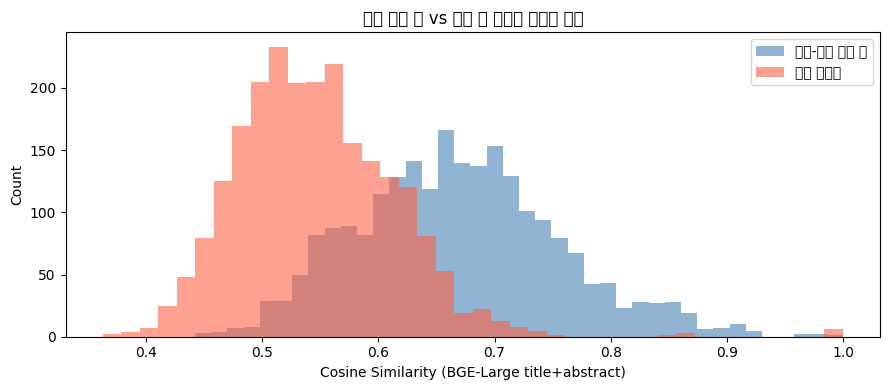

In [6]:
# [Cell 10] 원고-피고 쌍 텍스트 유사도 분포 분석
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import matplotlib

_available = {f.name for f in fm.fontManager.ttflist}
_font = next((f for f in ['NanumGothic','NanumBarunGothic','DejaVu Sans'] if f in _available), 'DejaVu Sans')
matplotlib.rcParams['font.family'] = _font
matplotlib.rcParams['axes.unicode_minus'] = False

valid = pairs.dropna(subset=['p_pid','d_pid']).copy()
valid['p_pid'] = valid['p_pid'].astype(int)
valid['d_pid'] = valid['d_pid'].astype(int)

# 임베딩 있는 쌍만
mask = valid['p_pid'].isin(pid_to_row) & valid['d_pid'].isin(pid_to_row)
valid = valid[mask].copy()
print(f'유사도 계산 가능한 쌍: {len(valid)}개')

p_embs = emb_text[[pid_to_row[p] for p in valid['p_pid']]]
d_embs = emb_text[[pid_to_row[d] for d in valid['d_pid']]]
pair_sims = (p_embs * d_embs).sum(axis=1)  # 이미 정규화됨

# 랜덤 쌍 대조군
np.random.seed(42)
rand_idx = np.random.choice(len(emb_text), size=len(p_embs), replace=True)
rand_sims = np.einsum('ij,ij->i', p_embs, emb_text[rand_idx])

print(f'원고-피고 쌍  cosine sim: mean={pair_sims.mean():.4f}  median={np.median(pair_sims):.4f}  '
      f'p25={np.percentile(pair_sims,25):.4f}  p75={np.percentile(pair_sims,75):.4f}')
print(f'랜덤 대조군   cosine sim: mean={rand_sims.mean():.4f}  median={np.median(rand_sims):.4f}  '
      f'p25={np.percentile(rand_sims,25):.4f}  p75={np.percentile(rand_sims,75):.4f}')

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(pair_sims, bins=40, alpha=0.6, label='원고-피고 실제 쌍', color='steelblue')
ax.hist(rand_sims, bins=40, alpha=0.6, label='랜덤 대조군',       color='tomato')
ax.set_xlabel('Cosine Similarity (BGE-Large title+abstract)')
ax.set_ylabel('Count')
ax.set_title('소송 특허 쌍 vs 랜덤 쌍 텍스트 유사도 분포')
ax.legend()
plt.tight_layout()
plt.savefig('./data_gnn/text_sim_distribution.png', dpi=150)
plt.show()

In [ ]:
# [Cell 11] 텍스트 임베딩 기반 Recall@K (후보 추출 성능)
# 원고 특허 텍스트 임베딩 → 1268개 후보 안에서 피고 순위
# (전체 556만 아닌 266케이스 특허 안에서의 recall — 상한선 확인용)

test_pairs = valid[valid['split'] == 'test']
Ks = [1, 3, 5, 10, 20, 50]
recalls = {k: [] for k in Ks}
mrrs = []

for case_id, grp in test_pairs.groupby('case_row_id'):
    p_pid = int(grp['p_pid'].iloc[0])
    d_pids = set(grp['d_pid'].astype(int).tolist())
    if p_pid not in pid_to_row: continue

    p_vec = emb_text[pid_to_row[p_pid]]
    sims  = emb_text @ p_vec
    sims[pid_to_row[p_pid]] = -1  # 자기 제외
    ranked_pids = pid_order[np.argsort(sims)[::-1]]

    for k in Ks:
        top_k = set(ranked_pids[:k].tolist())
        recalls[k].append(len(d_pids & top_k) / len(d_pids))

    first_rank = next((r+1 for r, pid in enumerate(ranked_pids) if pid in d_pids), None)
    mrrs.append(1/first_rank if first_rank else 0)

n_cases = test_pairs['case_row_id'].nunique()
print(f'=== 텍스트 임베딩(BGE) Recall@K — test {n_cases}케이스, 후보 {len(pid_order)}개 안에서 ===')
for k in Ks:
    print(f'  Recall@{k:3d}: {np.mean(recalls[k]):.4f}')
print(f'  MRR:       {np.mean(mrrs):.4f}')
print()
print('※ 이 수치는 1268개 특허 풀 안에서의 상한선입니다.')
print('  전체 556만 특허 대상 검색 시 Recall은 이보다 낮아집니다.')